# 04 Decision trees: a rule the data wrote

*Teaching material. Not for clinical use.*

On 2,438 patients, of whom 4.9% were massively transfused, ten model families were set against a transfusion score (E-90). One of the ten was a single decision tree: the kind of model a person can read.

**Before reading on, guess.** Of the ten, which fell short of an area under the curve of 0.75?

- None: every family cleared it
- The single decision tree
- Something more elaborate, such as a neural network
- Several of them

Write the guess down. It is not marked, and the answer comes in the diagnosis section below.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from sklearn.metrics import roc_curve
from sklearn.tree import DecisionTreeClassifier

from inference_labs import baseline
from inference_labs.lenses import frequentist as freq
from inference_labs.lenses import rules
from inference_labs.lenses import trees

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # needs intervention, does not, published figure
PALE = "#6baed6"                                      # a second series: lighter, and drawn hollow or hatched
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)

# 100,000 synthetic casualties, seed 42, military cohort, every stream. Every result on them is a mechanism.
observed, truth = baseline.generator_sample()
need = truth["needs_lsi"].to_numpy(bool)

## The idea, before any medicine

In the game of twenty questions one player thinks of something and the other asks yes-or-no questions. A good player does not ask "is it a giraffe?" first. They ask the question that splits what is left most evenly, "is it alive?", and then ask again inside whichever half the answer leaves. Each answer narrows the field until one guess is left.

**Plain.** A decision tree plays that game with casualties. It looks for the single question that best separates those who need help from those who do not, then asks again inside each group. Nobody writes the questions: the data do. One tree is easy to read and follow, but grow it on a slightly different crowd and it may ask different questions. Grow hundreds of trees on hundreds of crowds and average them, and the answer steadies; that is a forest, and nobody can read it.

**Developer.** Growing a tree is a greedy search:

```python
def grow(rows, depth):
    if depth == 0 or rows are pure: return leaf(share in need)
    best = max(every question "sign <= cut", key=lambda q: purity gained by splitting rows on q)
    return node(best, grow(rows where yes, depth - 1), grow(rows where no, depth - 1))
```

Trying every cut of every sign costs about n log n per sign per level. A forest grows a hundred such trees, each on a resample of the rows with a random subset of the signs at each split, and averages their answers. Here both use the same four of the MPTT-24's signs as lens 02's score, walking, conscious level, respiratory rate and heart rate, and the same 100,000 synthetic training casualties.

**Technical.** At a node holding a share $q$ in need, the Gini impurity is $G = 2q(1-q)$. A split into parts of sizes $n_L$ and $n_R$ is chosen to maximise

$$G - \frac{n_L}{n} G_L - \frac{n_R}{n} G_R,$$

and the leaf's prediction is its share in need. A deep tree has low bias and high variance: a small change in the rows changes the early splits, and everything below them. Averaging $B$ trees grown on bootstrap resamples, with features sampled at each split, cuts the variance without adding bias, at the cost of the single readable path.

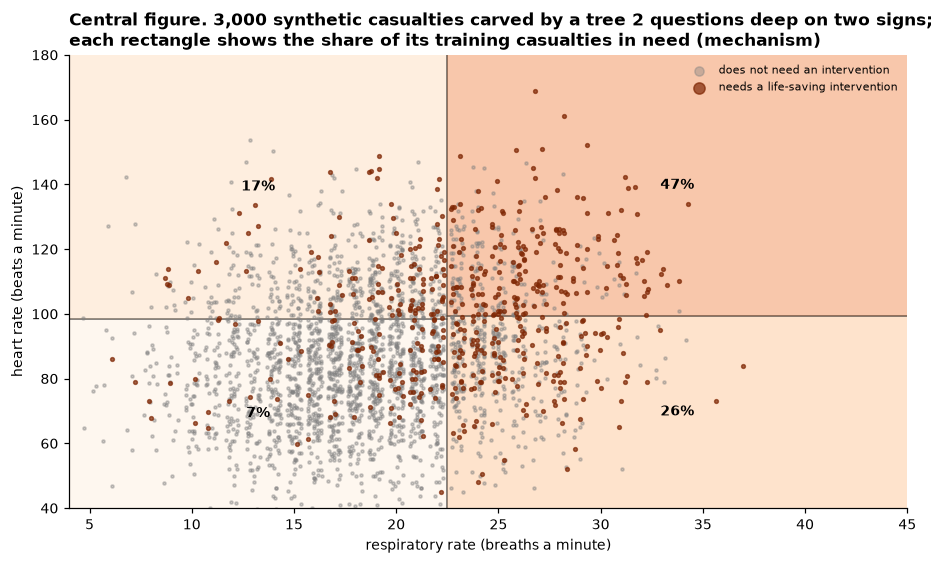

In [2]:
# Central figure: the carving. The control: change it and run the cell again.
DEPTH = 2        # how many questions deep: 1, 2 or 3

carve = trees.carving_tree(DEPTH)
t = carve.tree_
rng = np.random.default_rng(4)
show = rng.choice(len(observed), 3_000, replace=False)
rr = observed["respiratory_rate"].to_numpy(float)[show] + rng.uniform(-0.35, 0.35, show.size)
hr = observed["heart_rate"].to_numpy(float)[show] + rng.uniform(-0.35, 0.35, show.size)

def boxes(node, box):
    if t.children_left[node] == -1:
        v = t.value[node][0]
        return [(box, v[1] / v.sum())]
    f, th = t.feature[node], t.threshold[node]
    left, right = [list(b) for b in box], [list(b) for b in box]
    left[f][1], right[f][0] = th, th
    return boxes(t.children_left[node], left) + boxes(t.children_right[node], right)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for (rr_box, hr_box), share in boxes(0, [[0, 60], [30, 200]]):
    ax.add_patch(Rectangle((rr_box[0], hr_box[0]), rr_box[1] - rr_box[0], hr_box[1] - hr_box[0],
                           facecolor=plt.cm.Oranges(share * 1.4), edgecolor="black", linewidth=1, alpha=0.35))
    ax.text((max(rr_box[0], 4) + min(rr_box[1], 45)) / 2, (max(hr_box[0], 40) + min(hr_box[1], 180)) / 2,
            f"{share:.0%}", ha="center", va="center", fontsize=9, fontweight="bold")
ax.scatter(rr[~need[show]], hr[~need[show]], s=4, color="grey", alpha=0.4, label="does not need an intervention")
ax.scatter(rr[need[show]], hr[need[show]], s=6, color=DARK, alpha=0.7, label="needs a life-saving intervention")
ax.set_xlim(4, 45)
ax.set_ylim(40, 180)
ax.set_xlabel("respiratory rate (breaths a minute)")
ax.set_ylabel("heart rate (beats a minute)")
ax.legend(fontsize=7, frameon=False, loc="upper right", markerscale=3)
ax.set_title(f"Central figure. 3,000 synthetic casualties carved by a tree {DEPTH} questions deep on two signs;\n"
             f"each rectangle shows the share of its training casualties in need (mechanism)", loc="left")
plt.tight_layout()
plt.show()

Each dot is one synthetic casualty, and every result here is a **mechanism**: the signs are drawn from assumed distributions in the generator, so the carving shows how a tree reads the generator, not how real casualties fall. Change `DEPTH` and run the cell again: each extra level splits every rectangle once more.

## By hand: twenty casualties and one question

Below are twenty synthetic battle casualties, with whether each needs a life-saving intervention. Four questions are on offer: are they not walking, are they not alert, is the respiratory rate outside 12 to 23, is the heart rate 100 or more?

For each question, split the twenty into a yes group and a no group and count those in need on each side. The best question is the one that leaves the two groups purest: mostly in need on one side, mostly not on the other. Do it on paper before running the next cell.

In [3]:
ids = tuple(observed.loc[observed["stream"] == "battle", "id"].head(20))
twenty_obs, twenty_need = trees.twenty(ids)
table = twenty_obs[["id", "walking", "avpu", "respiratory_rate", "heart_rate"]].copy()
table["needs an intervention"] = twenty_need
print(table.to_string(index=False))

 id  walking avpu  respiratory_rate  heart_rate  needs an intervention
  2     True    A                14          91                  False
  4    False    A                23         118                  False
 10     True    A                17         103                  False
 13     True    A                21         126                   True
 15     True    A                27          77                  False
 17     True    A                20         109                  False
 20    False    V                26          94                  False
 27    False    U                20         124                   True
 30    False    A                18          99                   True
 35     True    A                26         112                   True
 38    False    A                22          86                  False
 40     True    A                23         118                  False
 41     True    A                28          99                   True
 43   

In [4]:
def gini(flags):                                    # the same count in plain Python
    q = sum(flags) / len(flags) if flags else 0
    return 2 * q * (1 - q)

rows = []
for name, question in trees.CANDIDATES:
    answers = question(twenty_obs)
    yes = [n for a, n in zip(answers, twenty_need) if a]
    no = [n for a, n in zip(answers, twenty_need) if not a]
    after = (len(yes) * gini(yes) + len(no) * gini(no)) / 20
    rows.append({"question": name, "yes": len(yes), "yes in need": sum(yes), "no": len(no), "no in need": sum(no),
                 "impurity after": round(after, 3), "gain": round(gini(list(twenty_need)) - after, 3)})
by_hand = pd.DataFrame(rows).set_index("question")
library = {name: trees.split_gain(q(twenty_obs), twenty_need)["gain"] for name, q in trees.CANDIDATES}
assert all(abs(by_hand.loc[n, "gain"] - round(g, 3)) < 1e-9 for n, g in library.items())   # the library agrees
stump = DecisionTreeClassifier(max_depth=1).fit(np.column_stack([q(twenty_obs) for _, q in trees.CANDIDATES]), twenty_need)
chosen = trees.CANDIDATES[stump.tree_.feature[0]][0] if stump.tree_.node_count > 1 else "none"
print(f"a library tree of depth one asks first: {chosen}")
assert chosen == "none" or by_hand.loc[chosen, "gain"] == by_hand["gain"].max()
by_hand

a library tree of depth one asks first: respiratory rate outside 12 to 23


,yes,yes in need,no,no in need,impurity after,gain
question,,,,,,
not walking,8,3,12,4,0.454,0.001
not alert,2,1,18,6,0.450,0.005
respiratory rate outside 12 to 23,5,3,15,4,0.413,0.042
heart rate 100 or more,8,4,12,3,0.425,0.030


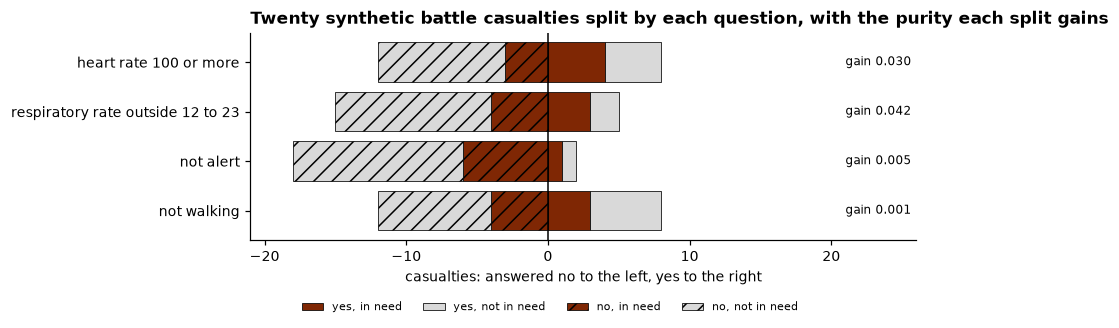

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(by_hand))
ax.barh(y, by_hand["yes in need"], color=DARK, edgecolor="black", linewidth=0.5, label="yes, in need")
ax.barh(y, by_hand["yes"] - by_hand["yes in need"], left=by_hand["yes in need"], color=LIGHT, edgecolor="black",
        linewidth=0.5, label="yes, not in need")
ax.barh(y, -by_hand["no in need"], color=DARK, edgecolor="black", linewidth=0.5, hatch="//", label="no, in need")
ax.barh(y, -(by_hand["no"] - by_hand["no in need"]), left=-by_hand["no in need"], color=LIGHT, edgecolor="black",
        linewidth=0.5, hatch="//", label="no, not in need")
for yi, g in zip(y, by_hand["gain"]):
    ax.text(21, yi, f"gain {g:.3f}", va="center", fontsize=8)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y, by_hand.index)
ax.set_xlim(-21, 26)
ax.set_xlabel("casualties: answered no to the left, yes to the right")
ax.legend(fontsize=7, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.25))
ax.set_title("Twenty synthetic battle casualties split by each question, with the purity each split gains", loc="left")
plt.tight_layout()
plt.show()

That count is all a tree does at each node. Written as notation, a share $q$ in need has impurity $2q(1-q)$; a question is scored by the impurity it removes, weighted by the size of each side, and the tree takes the best question and starts again inside each side.

## Diagnosis: one tree, a forest, a score and a rule

**The answer to the hook.** In E-90 every model family except the single decision tree and the support vector machine reached an area under the curve above 0.75, from 0.75 to 0.83. The readable model was one of the two that fell short.

The same thing can be asked on the generator. Below, the single tree three questions deep and a forest of 100 trees are set beside lens 02's logistic score and the MPTT-24, under the reading of its published figure and under the text reading that matches what E-09 measured, labelled as validated (D-24). All are scored on the same 100,000 synthetic casualties of the military cohort, every stream, and each model's threshold is set where its specificity on the training casualties comes closest to the rule's. Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the Joint Theatre Trauma Registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).

In [6]:
trees.comparison()

,area under the curve,sensitivity,specificity,Brier score,calibration
method,,,,,
"MPTT-24, figure (as published)",NaN,0.600,0.786,0.245,0.112
"MPTT-24, text (as validated)",NaN,0.614,0.778,0.249,0.121
logistic score (lens 02),0.814,0.682,0.787,0.110,0.001
single tree,0.765,0.655,0.746,0.117,-0.000
forest,0.815,0.686,0.786,0.109,0.000


In [7]:
print(trees.tree_text())

If respiratory rate 22 or less, and alert, and respiratory rate 18 or less: 5% need an intervention (40,719 training casualties)
If respiratory rate 22 or less, and alert, and respiratory rate 19 or more: 14% need an intervention (27,193 training casualties)
If respiratory rate 22 or less, and not alert, and respiratory rate 11 or less: 58% need an intervention (839 training casualties)
If respiratory rate 22 or less, and not alert, and respiratory rate 12 or more: 27% need an intervention (4,947 training casualties)
If respiratory rate 23 or more, and not walking, and heart rate 95 or less: 34% need an intervention (7,330 training casualties)
If respiratory rate 23 or more, and not walking, and heart rate 96 or more: 57% need an intervention (7,197 training casualties)
If respiratory rate 23 or more, and walking, and heart rate 112 or less: 18% need an intervention (9,742 training casualties)
If respiratory rate 23 or more, and walking, and heart rate 113 or more: 39% need an interven

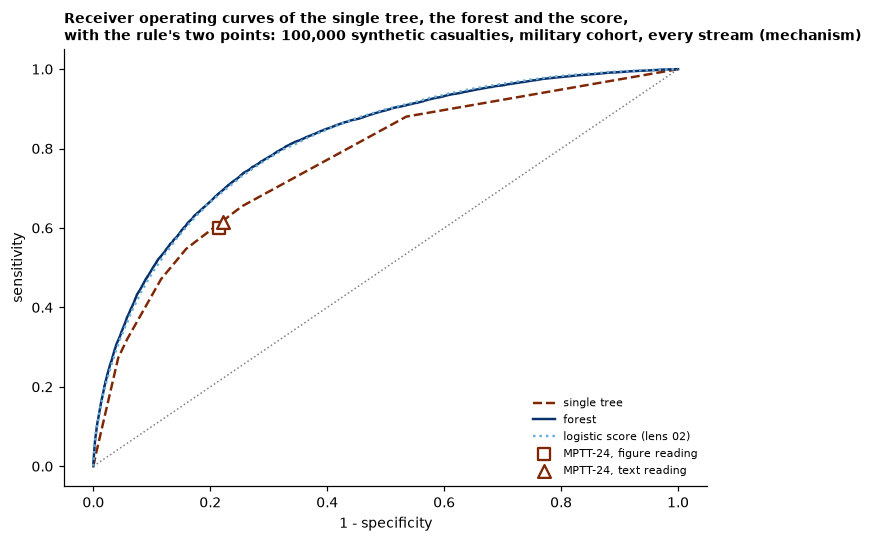

In [8]:
probs = trees.probabilities(observed)
fig, ax = plt.subplots(figsize=(6.6, 5))
for name, p, colour, style in (("single tree", probs["single tree"], DARK, "--"), ("forest", probs["forest"], MID, "-"),
                               ("logistic score (lens 02)", freq.probability(observed), PALE, ":")):
    fpr, tpr, _ = roc_curve(need, p)
    ax.plot(fpr, tpr, style, color=colour, linewidth=1.6, label=name)
for reading, marker in (("figure", "s"), ("text", "^")):
    r = baseline.diagnosis_results("pre_hospital", reading)
    ax.scatter(1 - r["specificity"], r["sensitivity"], s=70, marker=marker, facecolor="white", edgecolor=DARK,
               linewidth=1.5, zorder=4, label=f"MPTT-24, {reading} reading")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("1 - specificity")
ax.set_ylabel("sensitivity")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("Receiver operating curves of the single tree, the forest and the score,\nwith the rule's two points: "
             "100,000 synthetic casualties, military cohort, every stream (mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

### What the published comparisons say

The published record points two ways, and both are set out here without a verdict.

- **The forest first.** Across 21 studies and 50 transfusion prediction models, the pooled area under the curve was 0.89 for random forests (0.85 to 0.93), 0.88 for neural networks and 0.86 for XGBoost (E-91). The median quality score was 51 of 100; no study met every reporting item and most had no external validation.
- **The readable model.** One argument holds that explaining a black box after the fact is unreliable for high-stakes decisions, and calls the assumed trade between accuracy and interpretability a myth for structured data with meaningful features (E-118).

Two more results bear on the question. A prognostic model for death from bleeding, studied in 13,485 CRASH-2 patients and 9,945 from a French registry, reached a C-statistic of 0.84 from three variables, age, systolic pressure and GCS, and 0.85 when heart rate, respiratory rate and penetrating injury were added (E-30). And a decision rule derived and validated on 42,412 children in 25 emergency departments, with six predictors for those aged two and over, found 61 of 63 clinically important brain injuries in that group in validation, a sensitivity of 96.8% (89.0 to 99.6) (E-89).

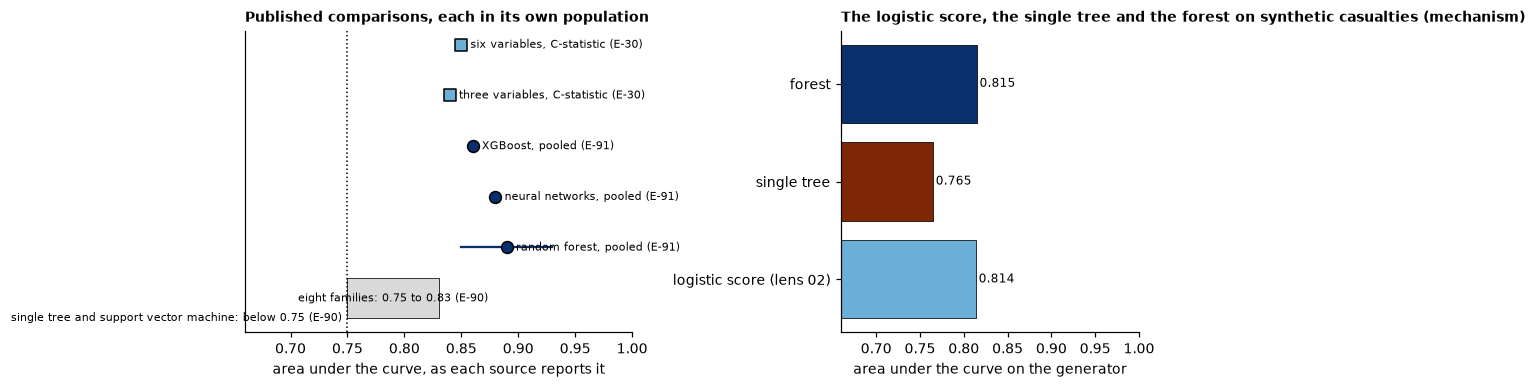

In [9]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax.barh(0, 0.83 - 0.75, left=0.75, color=LIGHT, edgecolor="black", linewidth=0.5)
ax.text(0.79, 0, "eight families: 0.75 to 0.83 (E-90)", ha="center", va="center", fontsize=7)
ax.text(0.745, -0.45, "single tree and support vector machine: below 0.75 (E-90)", ha="right", fontsize=7)
ax.axvline(0.75, color="black", linestyle=":", linewidth=1)
for i, (name, auc, ci) in enumerate((("random forest", 0.89, (0.85, 0.93)), ("neural networks", 0.88, None),
                                     ("XGBoost", 0.86, None)), start=1):
    ax.scatter(auc, i, s=60, color=MID, edgecolor="black", zorder=3)
    if ci:
        ax.plot(ci, [i, i], color=MID, linewidth=1.5)
    ax.text(auc + 0.008, i, f"{name}, pooled (E-91)", va="center", fontsize=7)
for i, (name, auc) in enumerate((("three variables", 0.84), ("six variables", 0.85)), start=4):
    ax.scatter(auc, i, s=60, marker="s", color=PALE, edgecolor="black", zorder=3)
    ax.text(auc + 0.008, i, f"{name}, C-statistic (E-30)", va="center", fontsize=7)
ax.set_yticks([])
ax.set_xlim(0.66, 1.0)
ax.set_xlabel("area under the curve, as each source reports it")
ax.set_title("Published comparisons, each in its own population", loc="left", fontsize=9)
comp = trees.comparison().dropna(subset=["area under the curve"])
bx.barh(range(len(comp)), comp["area under the curve"], color=[PALE, DARK, MID], edgecolor="black", linewidth=0.5)
for i, v in enumerate(comp["area under the curve"]):
    bx.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
bx.set_yticks(range(len(comp)), comp.index)
bx.set_xlim(0.66, 1.0)
bx.set_xlabel("area under the curve on the generator")
bx.set_title("The logistic score, the single tree and the forest on synthetic casualties (mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

### A tree with three cues and no data at all

A fast-and-frugal tree asks a few cues in a fixed order, and each cue but the last has one exit. Its exit structure corresponds directly to the decision criterion in signal detection, and its sensitivity depends on the order and properties of its cues (E-59). Here three cues are asked in order: not walking, a heart rate of 100 or more, a respiratory rate outside 12 to 23, the MPTT-24's own thresholds (E-08). The first two cues can each exit on a yes (flag the casualty) or on a no (clear them). Four exit structures, the same three cues.

,sensitivity,specificity
exits of the first two cues,,
"yes, yes",0.933,0.311
"yes, no",0.802,0.500
"no, yes",0.544,0.803
"no, no",0.198,0.970


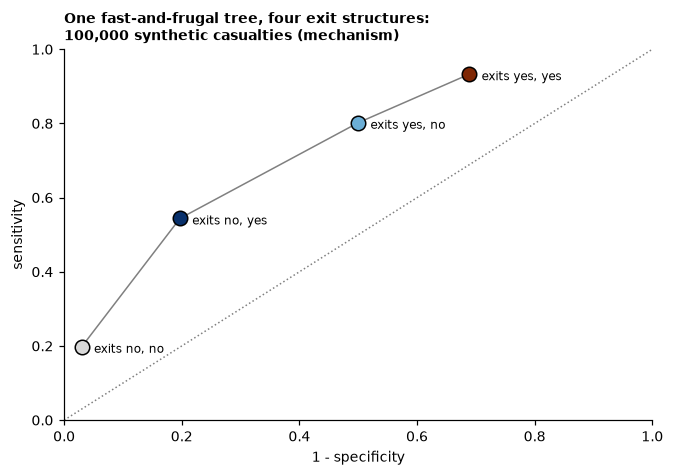

In [10]:
fft = trees.fft_table()
display(fft)
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.plot(1 - fft["specificity"], fft["sensitivity"], color="grey", linewidth=1, zorder=1)
for (exits, row), colour in zip(fft.iterrows(), (DARK, PALE, MID, LIGHT)):
    ax.scatter(1 - row["specificity"], row["sensitivity"], s=90, color=colour, edgecolor="black", zorder=3)
    ax.annotate(f"exits {exits}", (1 - row["specificity"], row["sensitivity"]), xytext=(8, -4),
                textcoords="offset points", fontsize=8)
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("1 - specificity")
ax.set_ylabel("sensitivity")
ax.set_title("One fast-and-frugal tree, four exit structures:\n100,000 synthetic casualties (mechanism)", loc="left",
             fontsize=9)
plt.tight_layout()
plt.show()

### A relation that bends

In the prognostic model for death from bleeding, heart rate and respiratory rate showed U-shaped relations to the risk (E-30). A single linear term cannot bend: it can say risk rises with the rate or falls with it, not both. A tree has no such limit, because it only asks which side of a cut a value falls.

The generator has a two-sided respiratory rate by assumption: it is raised by bleeding, tension pneumothorax, sepsis and injury, and slowed in a share of severe head injuries. On respiratory rate alone, a linear term and a tree five questions deep are fitted to the training casualties and set against the share in need at each rate.

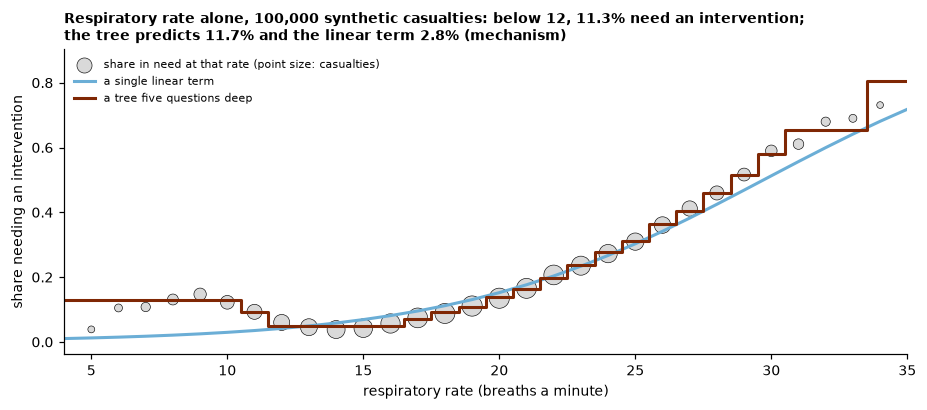

In [11]:
u = trees.u_shape()
s = trees.u_summary()
shown = u[u["casualties"] >= 50]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.scatter(shown["respiratory rate"], shown["share in need"], s=np.sqrt(shown["casualties"]) * 2, color=LIGHT,
           edgecolor="black", linewidth=0.4, label="share in need at that rate (point size: casualties)")
ax.plot(u["respiratory rate"], u["linear term"], color=PALE, linewidth=2, label="a single linear term")
ax.step(u["respiratory rate"], u["tree"], where="mid", color=DARK, linewidth=2, label="a tree five questions deep")
ax.set_xlim(shown["respiratory rate"].min() - 1, shown["respiratory rate"].max() + 1)
ax.set_xlabel("respiratory rate (breaths a minute)")
ax.set_ylabel("share needing an intervention")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title(f"Respiratory rate alone, 100,000 synthetic casualties: below 12, {s['share in need below 12']:.1%} need an "
             f"intervention;\nthe tree predicts {s['tree below 12']:.1%} and the linear term {s['linear term below 12']:.1%} "
             f"(mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## Treatment: who gets blood first

This section is about treatment decisions, and its results are kept apart from the diagnosis results above.

Lens 01 coded the ABC score: four yes-or-no items, a penetrating mechanism, a positive scan, a systolic pressure of 90 mm Hg or less and a heart rate of 120 or more, with a score of 2 or more predicting massive transfusion (E-31). The register does not describe the score's 596 patients as military, so applying the score to a military casualty is an assumption. A tree can be given the same four items, with pressure and heart rate as numbers rather than yes or no, and left to find its own cuts.

The generator records neither penetration nor massive transfusion, so the assumptions of lens 01 carry over: small arms injuries count as penetrating, and significant bleeding stands in for the need for transfusion. The scan item is the generator's scan for free fluid, read where it was done. The tree is fitted on the training sample's battle casualties and scored on the evaluation sample's, with its threshold set where its specificity comes closest to the ABC score's. Beside them, lens 01's doctrine rule needs three of four items, two of them haematocrit and pH (E-86).

In [12]:
rows = []
for setting in trees.SETTINGS:
    r = trees.treatment_results(setting)
    rows.append({"scan": baseline.SETTING_NAMES[setting], "method": "ABC score 2 or more",
                 "sensitivity": r["abc"]["sensitivity"][0], "specificity": r["abc"]["specificity"][0]})
    rows.append({"scan": baseline.SETTING_NAMES[setting], "method": "treatment tree, nearest the ABC score's specificity",
                 "sensitivity": r["tree"]["sensitivity"][0], "specificity": r["tree"]["specificity"][0]})
bedside = trees.treatment_results("pre_hospital")["doctrine bedside items"]
print(f"doctrine rule: synthetic battle casualties reaching three of four items without a laboratory: "
      f"{int((bedside >= rules.DOCTRINE_NEEDS).sum())} of {len(bedside):,}")
pd.DataFrame(rows).set_index(["scan", "method"]).round(3)

doctrine rule: synthetic battle casualties reaching three of four items without a laboratory: 0 of 29,925


sensitivity  \
scan                 method                                                             
scan before hospital ABC score 2 or more                                        0.239   
                     treatment tree, nearest the ABC score's specificity        0.535   
scan in hospital     ABC score 2 or more                                        0.315   
                     treatment tree, nearest the ABC score's specificity        0.558   

                                                                          specificity  
scan                 method                                                            
scan before hospital ABC score 2 or more                                        0.940  
                     treatment tree, nearest the ABC score's specificity        0.946  
scan in hospital     ABC score 2 or more                                        0.948  
                     treatment tree, nearest the ABC score's specificity        0.961

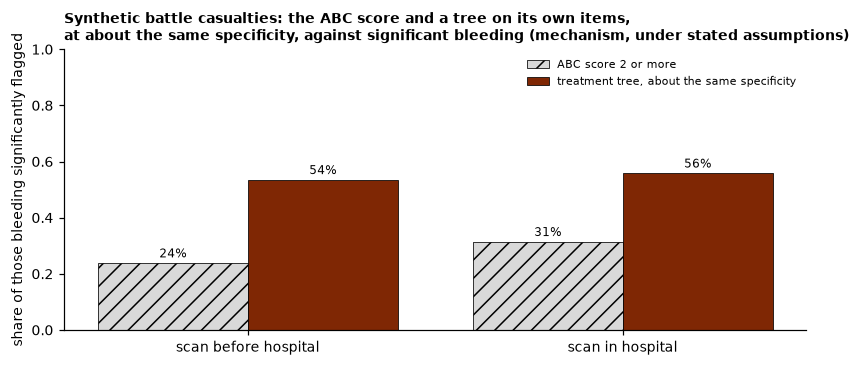

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(trees.SETTINGS))
abc = [trees.treatment_results(s)["abc"]["sensitivity"][0] for s in trees.SETTINGS]
tree_ = [trees.treatment_results(s)["tree"]["sensitivity"][0] for s in trees.SETTINGS]
ax.bar(x - 0.2, abc, 0.4, color=LIGHT, edgecolor="black", hatch="//", linewidth=0.5, label="ABC score 2 or more")
ax.bar(x + 0.2, tree_, 0.4, color=DARK, edgecolor="black", linewidth=0.5, label="treatment tree, about the same specificity")
for xi, a, b in zip(x, abc, tree_):
    ax.text(xi - 0.2, a + 0.02, f"{a:.0%}", ha="center", fontsize=8)
    ax.text(xi + 0.2, b + 0.02, f"{b:.0%}", ha="center", fontsize=8)
ax.set_xticks(x, [baseline.SETTING_NAMES[s] for s in trees.SETTINGS])
ax.set_ylim(0, 1)
ax.set_ylabel("share of those bleeding significantly flagged")
ax.legend(fontsize=7, frameon=False)
ax.set_title("Synthetic battle casualties: the ABC score and a tree on its own items,\nat about the same specificity, "
             "against significant bleeding (mechanism, under stated assumptions)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## The failure: twenty samples, twenty trees, and a variable from the future

**Instability.** Take 300 training casualties and grow a tree two questions deep. Take another 300 and grow another. Twenty samples give the trees below. A tree grown on all 100,000 asks first whether the respiratory rate is 23 or more; on 300 the first question and its cut wander.

**Leakage.** A tree splits on whatever separates the groups, including the answer. To show it, a variable is constructed here that stands for something recorded after the decision, such as what an operation found. It is built from the generator's truth plus noise, so it leaks the answer by construction, and it is not a generator variable. Given it, the tree asks about it first and its accuracy jumps; at the point of the decision it does not exist.

In [14]:
unstable = trees.instability()
print(f"tree on all {freq.TRAIN_N:,} training casualties asks first: {trees.stable_root()}")
unstable

tree on all 100,000 training casualties asks first: respiratory rate 23 or more


,first question,second questions
sample,,
1,respiratory rate 24 or more,"conscious level P, U; heart rate 126 or more"
2,not alert,respiratory rate 29 or more; heart rate 104 or more
3,respiratory rate 22 or more,conscious level U; heart rate 124 or more
4,respiratory rate 24 or more,heart rate 150 or more; walking
5,respiratory rate 27 or more,heart rate 129 or more; walking
6,respiratory rate 21 or more,heart rate 103 or more; heart rate 55 or more
7,respiratory rate 22 or more,conscious level U; walking
8,respiratory rate 22 or more,not alert; walking
9,respiratory rate 22 or more,conscious level U; heart rate 82 or more


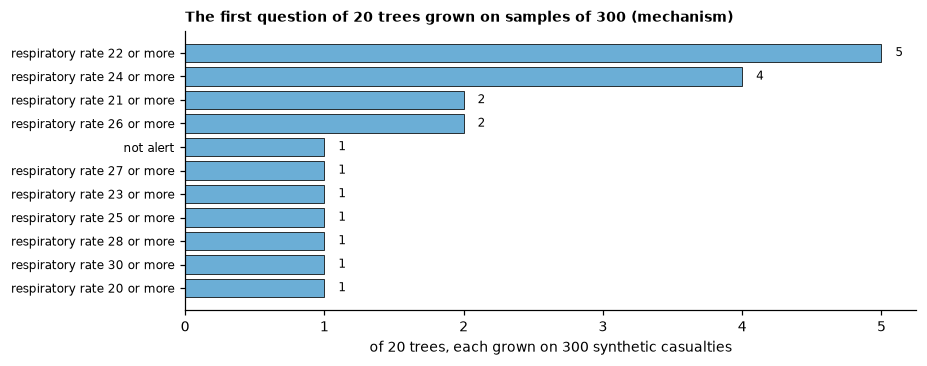

In [15]:
counts = unstable["first question"].value_counts()
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh(range(len(counts)), counts.values, color=PALE, edgecolor="black", linewidth=0.5)
ax.set_yticks(range(len(counts)), counts.index, fontsize=8)
ax.invert_yaxis()
for i, v in enumerate(counts.values):
    ax.text(v + 0.1, i, str(v), va="center", fontsize=8)
ax.set_xlabel(f"of {trees.RESAMPLES} trees, each grown on {trees.SMALL_N} synthetic casualties")
ax.set_title(f"The first question of {trees.RESAMPLES} trees grown on samples of {trees.SMALL_N} (mechanism)", loc="left",
             fontsize=9)
plt.tight_layout()
plt.show()

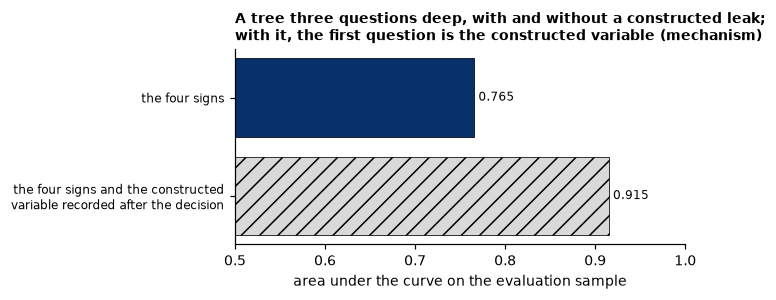

In [16]:
leak = trees.leakage()
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh([1, 0], [leak["without"], leak["with"]], color=[MID, LIGHT], edgecolor="black", linewidth=0.5,
        hatch=["", "//"])
for y, v in ((1, leak["without"]), (0, leak["with"])):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks([1, 0], ["the four signs", "the four signs and the constructed\nvariable recorded after the decision"],
              fontsize=8)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("area under the curve on the evaluation sample")
ax.set_title(f"A tree three questions deep, with and without a constructed leak;\nwith it, the first question is "
             f"{leak['first question']} (mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label: synthetic data can only confirm the model that made them. Axes 3, 4 and 5 are stated. Axis 7, the value of the decision, comes from the decision theory lens (notebook 10): net benefit at a threshold of 0.10 for every lens (D-26), the value its default costs set, with a miss weighed nine times a false alarm, an assumption for the reader to change. It is given for every stream and for the battle casualties alone. Half of the battle casualties need an intervention, far above 0.10, and among them treating everyone has a higher net benefit than every method scored (mechanism).

The diagnosis columns score the single tree and the forest against need for a life-saving intervention on all 100,000 synthetic casualties of the military cohort, every stream. The baseline is the MPTT-24 read as its figure was published, with the text reading beside it, labelled as validated (D-24). Among the generator's injured, 26.5% need a life-saving intervention, against 47.6% Priority 1 in the Joint Theatre Trauma Registry (E-01, E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The treatment column scores the treatment tree against significant bleeding on the battle casualties, under the assumptions stated in the treatment case. Axes 1 and 6 use each model's own threshold; axis 7 uses 0.10 (D-26), at which the treatment tree flags every battle casualty, so there its net benefit is exactly that of treating all. Fit is native for both: sorting casualties by a few questions is what a tree does.

In [17]:
with pd.option_context("display.max_colwidth", None):
    display(trees.seven_axes())

,diagnosis: single tree,diagnosis: forest,"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)",treatment: tree for bleeding
axis,,,,,
1 Discrimination (mechanism),"sensitivity 65.5%, specificity 74.6%, area under the curve 0.765; all 100,000 synthetic casualties of the military cohort, disease included","sensitivity 68.6%, specificity 78.6%, area under the curve 0.815; all 100,000 synthetic casualties of the military cohort, disease included","sensitivity 60.0%, specificity 78.6%","sensitivity 61.4%, specificity 77.8%","sensitivity 53.5%, specificity 94.6%, area under the curve 0.827; significant bleeding, battle casualties, scan before hospital. ABC score: sensitivity 23.9%, specificity 94.0%"
2 Calibration (mechanism),Brier 0.117; mean probability minus share in need -0.000,Brier 0.109; mean probability minus share in need +0.000,"Brier 0.245; it flags 11.2 points more than are in need. A rule gives no probability, so the Brier score is the share misclassified",Brier 0.249; it flags 12.1 points more than are in need,Brier 0.147; mean probability minus share in need +0.002
3 Uncertainty expressed,A share in need for each leaf,"A probability, the average over the trees",None: a priority,None: a priority,A share bleeding for each leaf
4 What it needed,"Labelled cases: 100,000 synthetic casualties (mechanism)","Labelled cases: 100,000 synthetic casualties, 100 trees (mechanism)",Rules only at the point of use (E-08),Rules only at the point of use (E-08),"Labelled cases: the battle casualties among 100,000 synthetic casualties (mechanism)"
5 Readability,"Three questions deep, 8 leaves: a medic can follow it on a card",100 trees averaged: it cannot be followed by hand,"Six yes-or-no steps, one observation each","Six yes-or-no steps, one observation each",Three questions deep: a medic can follow it on a card
"6 Robustness, setting changed (mechanism)","Scan in hospital: sensitivity 65.5%, specificity 74.6%, area under the curve 0.765, unchanged because in the generator the setting changes only the scan","Scan in hospital: sensitivity 68.6%, specificity 78.6%, area under the curve 0.815, unchanged for the same reason",Unchanged,Unchanged,"Scan in hospital: sensitivity 55.8%, specificity 96.1%, area under the curve 0.854. The scan item is more often right in hospital"
7 Decision value,"Net benefit 9.8 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism). Battle casualties alone, where 50.2% need it against a threshold of 0.10: net benefit 41.3 (below treating all), treat all 44.6","Net benefit 10.5 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism). Battle casualties alone, where 50.2% need it against a threshold of 0.10: net benefit 41.3 (below treating all), treat all 44.6","Net benefit 8.0 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism). Battle casualties alone, where 50.2% need it against a threshold of 0.10: net benefit 30.0 (below treating all), treat all 44.6","Net benefit 8.2 per 100 at a threshold of 0.10, with a miss weighed 9 times a false alarm (an assumption); treat all 7.4, treat none 0 (mechanism). Battle casualties alone, where 50.2% need it against a threshold of 0.10: net benefit 30.7 (below treating all), treat all 44.6","Net benefit 29.1 per 100 at a threshold of 0.10 (it flags every casualty at this threshold, so it scores exactly as treating all), with a miss weighed 9 times a false alarm (an assumption); treat all 29.1, treat none 0 (mechanism), against significant bleeding, battle casualties, scan before hospital"


In [18]:
card = pd.DataFrame([vars(row) for row in trees.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, single tree against need for a life-saving intervention, scan before hospital",6.546e-01,0.600,mechanism,native,generator
1,diagnosis,"specificity, single tree against need for a life-saving intervention, scan before hospital",7.459e-01,0.786,mechanism,native,generator
2,diagnosis,"Brier score, single tree against need for a life-saving intervention, scan before hospital",1.169e-01,0.245,mechanism,native,generator
3,diagnosis,"mean probability minus share in need, single tree against need for a life-saving intervention, scan before hospital",-3.000e-04,0.112,mechanism,native,generator
4,diagnosis,"sensitivity, forest against need for a life-saving intervention, scan before hospital",6.865e-01,0.600,mechanism,native,generator
5,diagnosis,"specificity, forest against need for a life-saving intervention, scan before hospital",7.859e-01,0.786,mechanism,native,generator
6,diagnosis,"Brier score, forest against need for a life-saving intervention, scan before hospital",1.087e-01,0.245,mechanism,native,generator
7,diagnosis,"mean probability minus share in need, forest against need for a life-saving intervention, scan before hospital",4.000e-04,0.112,mechanism,native,generator
8,diagnosis,"sensitivity, single tree against need for a life-saving intervention, scan in hospital",6.546e-01,0.600,mechanism,native,generator
9,diagnosis,"specificity, single tree against need for a life-saving intervention, scan in hospital",7.459e-01,0.786,mechanism,native,generator


Two rows carry the lesson. The forest's discrimination matches lens 02's score and beats the single tree, while the single tree is the only one of the three a medic could follow on a card. And the treatment tree finds more of those bleeding than the ABC score at about the same specificity, on the generator's battle casualties and under the assumptions of lens 01.

**Teach back.** In one sentence, why does averaging many trees steady the answer, and what does it cost?

## The brain analogy, and where it breaks

**What it resembles.** Fast-and-frugal trees, a few cues checked in order. The trees search little information, are robust, and adapt to the payoff structure of the task (E-59). A medic who asks "can they walk, are they breathing fast, is the pulse racing?" and stops at the first answer that settles it is reasoning in this shape.

**Where it breaks.** The resemblance is loose: a description of how some decisions can be made, not a mechanism of how a brain makes them. A grown tree is fitted to its sample and changes when the sample does; a person's cues are not chosen by impurity, and nobody averages a hundred of themselves.